football has been the biggest passion of my life since i was six years old every weekend my friends and i play on the small ground near our college running passing and shouting until the sun goes down watching professional matches teaches me how teams build attacks patiently and defend together as a unit my favourite players are the ones who keep working hard even when their team is losing playing regularly has also improved my fitness and it has taught me discipline and teamwork i hope to play for the college team next year and win the interuniversity tournament
['Football', 'has', 'been', 'the', 'biggest', 'passion', 'of', 'my', 'life', 'since', 'I', 'was', 'six', 'years', 'old', '.', 'Every', 'weekend', 'my', 'friends', 'and', 'I', 'play', 'on', 'the', 'small', 'ground', 'near', 'our', 'college', ',', 'running', ',', 'passing', 'and', 'shouting', 'until', 'the', 'sun', 'goes', 'down', '.', 'Watching', 'professional', 'matches', 'teaches', 'me', 'how', 'teams', 'build', 'attacks', 'p

<Axes: xlabel='Samples', ylabel='Counts'>

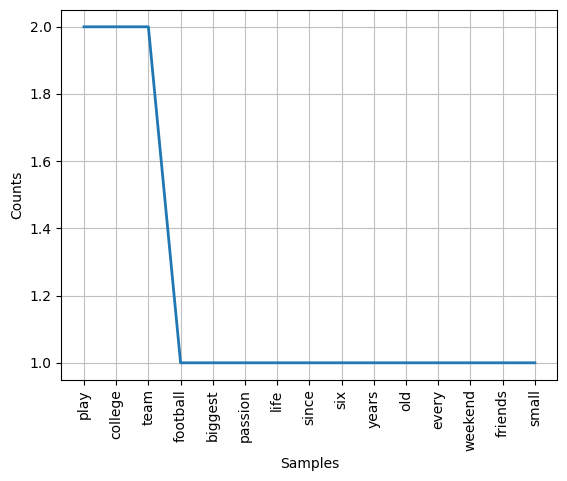

In [1]:
import re
import nltk
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk import FreqDist

for p in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(p, quiet=True)

stop_words = set(stopwords.words("english"))

para = "Football has been the biggest passion of my life since I was six years old. Every weekend my friends and I play on the small ground near our college, running, passing and shouting until the sun goes down. Watching professional matches teaches me how teams build attacks patiently and defend together as a unit. My favourite players are the ones who keep working hard even when their team is losing. Playing regularly has also improved my fitness, and it has taught me discipline and teamwork. I hope to play for the college team next year and win the inter-university tournament."

clean = re.sub(r"[^\w\s]", "", para.lower())
print(clean)

words = word_tokenize(para)
sents = sent_tokenize(para)
print(words)
print(sents)

print(para.split())
print(word_tokenize(para))
print("split() only cuts on spaces, so punctuation stays stuck to words like college, and inter-university stays whole, while word_tokenize separates punctuation marks into their own tokens")

no_stop = [w for w in clean.split() if w not in stop_words]
print(no_stop)

fd = FreqDist(no_stop)
print(fd.most_common(10))
fd.plot(15)

In [2]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

alpha = re.findall(r"[a-zA-Z]+", para.lower())
print(alpha)

filtered = [w for w in alpha if w not in stop_words]
print(filtered)

ps = PorterStemmer()
stemmed = [ps.stem(w) for w in filtered]
print(stemmed)

wl = WordNetLemmatizer()
lemmas = [wl.lemmatize(w, pos="v") for w in filtered]
print(lemmas)

for w, s, l in zip(filtered, stemmed, lemmas):
    if s != l:
        print(w, s, l)

print("stemming is faster and fine for search or indexing where exact words do not matter, lemmatization gives real dictionary words and is better when meaning and readability matter")

['football', 'has', 'been', 'the', 'biggest', 'passion', 'of', 'my', 'life', 'since', 'i', 'was', 'six', 'years', 'old', 'every', 'weekend', 'my', 'friends', 'and', 'i', 'play', 'on', 'the', 'small', 'ground', 'near', 'our', 'college', 'running', 'passing', 'and', 'shouting', 'until', 'the', 'sun', 'goes', 'down', 'watching', 'professional', 'matches', 'teaches', 'me', 'how', 'teams', 'build', 'attacks', 'patiently', 'and', 'defend', 'together', 'as', 'a', 'unit', 'my', 'favourite', 'players', 'are', 'the', 'ones', 'who', 'keep', 'working', 'hard', 'even', 'when', 'their', 'team', 'is', 'losing', 'playing', 'regularly', 'has', 'also', 'improved', 'my', 'fitness', 'and', 'it', 'has', 'taught', 'me', 'discipline', 'and', 'teamwork', 'i', 'hope', 'to', 'play', 'for', 'the', 'college', 'team', 'next', 'year', 'and', 'win', 'the', 'inter', 'university', 'tournament']
['football', 'biggest', 'passion', 'life', 'since', 'six', 'years', 'old', 'every', 'weekend', 'friends', 'play', 'small', 'g

In [3]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd

texts = [
    "The new phone has an amazing camera and a great battery life",
    "Heavy rain caused flooding in the city and many roads are closed",
    "The football team won the final match with a late goal in the second half"
]

cv = CountVectorizer(stop_words="english")
bow = cv.fit_transform(texts)
bow_df = pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out())
print(bow_df)

tv = TfidfVectorizer(stop_words="english")
tf = tv.fit_transform(texts)
tf_df = pd.DataFrame(tf.toarray(), columns=tv.get_feature_names_out())
print(tf_df.round(3))

for i in range(len(texts)):
    top = tf_df.iloc[i].sort_values(ascending=False).head(3)
    print(i + 1, top.round(3).to_dict())

print("words with the highest tf-idf score appear in only one text and are used there, so they describe what that text is about, while words like the or and appear in many texts and score lower")

   amazing  battery  camera  caused  city  closed  final  flooding  football  \
0        1        1       1       0     0       0      0         0         0   
1        0        0       0       1     1       1      0         1         0   
2        0        0       0       0     0       0      1         0         1   

   goal  ...  late  life  match  new  phone  rain  roads  second  team  won  
0     0  ...     0     1      0    1      1     0      0       0     0    0  
1     0  ...     0     0      0    0      0     1      1       0     0    0  
2     1  ...     1     0      1    0      0     0      0       1     1    1  

[3 rows x 23 columns]
   amazing  battery  camera  caused   city  closed  final  flooding  football  \
0    0.378    0.378   0.378   0.000  0.000   0.000  0.000     0.000     0.000   
1    0.000    0.000   0.000   0.378  0.378   0.378  0.000     0.378     0.000   
2    0.000    0.000   0.000   0.000  0.000   0.000  0.333     0.000     0.333   

    goal  ...   lat

In [4]:
from sklearn.metrics.pairwise import cosine_similarity

t1 = "Artificial intelligence lets machines learn from data and make decisions. Neural networks are trained on large datasets to recognise images and language. AI is used in healthcare, finance and self driving cars. It improves with more data and more computing power."
t2 = "Blockchain is a distributed ledger that records transactions in linked blocks. Every block is secured with cryptography and verified by many computers. It is used in cryptocurrency, supply chains and digital contracts. Once data is written to the chain it is very hard to change."

def prep(t):
    t = re.sub(r"[^\w\s]", "", t.lower())
    return [w for w in word_tokenize(t) if w not in stop_words]

a = prep(t1)
b = prep(t2)
print(a)
print(b)

sa, sb = set(a), set(b)
jaccard = len(sa & sb) / len(sa | sb)
print(sa & sb)
print(jaccard)

vec = TfidfVectorizer(stop_words="english")
m = vec.fit_transform([t1, t2])
cosine = cosine_similarity(m[0], m[1])[0][0]
print(cosine)

print("jaccard only checks whether words are shared and ignores how often or how important they are, cosine with tf-idf weights words by importance, so it gives a better idea of how related the two technologies are, and here both scores are low because the topics are different")

['artificial', 'intelligence', 'lets', 'machines', 'learn', 'data', 'make', 'decisions', 'neural', 'networks', 'trained', 'large', 'datasets', 'recognise', 'images', 'language', 'ai', 'used', 'healthcare', 'finance', 'self', 'driving', 'cars', 'improves', 'data', 'computing', 'power']
['blockchain', 'distributed', 'ledger', 'records', 'transactions', 'linked', 'blocks', 'every', 'block', 'secured', 'cryptography', 'verified', 'many', 'computers', 'used', 'cryptocurrency', 'supply', 'chains', 'digital', 'contracts', 'data', 'written', 'chain', 'hard', 'change']
{'used', 'data'}
0.04081632653061224
0.06284459666975663
jaccard only checks whether words are shared and ignores how often or how important they are, cosine with tf-idf weights words by importance, so it gives a better idea of how related the two technologies are, and here both scores are low because the topics are different


                                                    review  polarity  subjectivity    label
   The food was delicious and the staff were very friendly     0.744         0.825 positive
Terrible service, we waited an hour and the pasta was cold    -0.800         1.000 negative
         Great ambiance and wonderful desserts, I loved it     0.833         0.850 positive
      The restaurant is on the main road and opens at noon     0.167         0.333  neutral
   Very rude waiter and overpriced menu, I am disappointed    -0.570         0.765 negative
     Amazing biryani, fresh ingredients and quick delivery     0.411         0.633 positive
      We booked a table for seven people on Friday evening     0.000         0.000  neutral
        Excellent value for money and a lovely clean place     0.622         0.817 positive


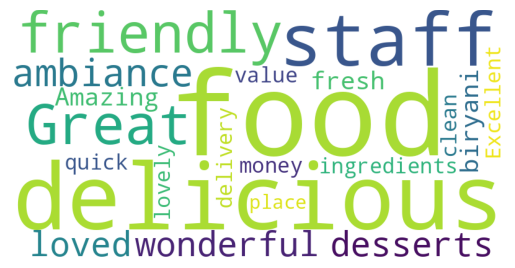

In [5]:
from textblob import TextBlob
from wordcloud import WordCloud

reviews = [
    "The food was delicious and the staff were very friendly",
    "Terrible service, we waited an hour and the pasta was cold",
    "Great ambiance and wonderful desserts, I loved it",
    "The restaurant is on the main road and opens at noon",
    "Very rude waiter and overpriced menu, I am disappointed",
    "Amazing biryani, fresh ingredients and quick delivery",
    "We booked a table for seven people on Friday evening",
    "Excellent value for money and a lovely clean place"
]

rows = []
for r in reviews:
    s = TextBlob(r).sentiment
    if s.polarity > 0.2:
        label = "positive"
    elif s.polarity < -0.2:
        label = "negative"
    else:
        label = "neutral"
    rows.append({"review": r, "polarity": round(s.polarity, 3), "subjectivity": round(s.subjectivity, 3), "label": label})

res = pd.DataFrame(rows)
print(res.to_string(index=False))

pos_text = " ".join(res[res["label"] == "positive"]["review"])
wc = WordCloud(width=800, height=400, background_color="white").generate(pos_text)
plt.imshow(wc)
plt.axis("off")
plt.show()

In [6]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import pad_sequences, to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

np.random.seed(1)
tf.random.set_seed(1)

data = "I love to play football with my friends every evening. We run on the ground and pass the ball to each other. Football teaches us teamwork and discipline. We practice hard every day to win the match. After the game we sit together and talk about the goals. The coach tells us to keep learning and keep playing. Our team is small but we play with a lot of heart. I want to play for the college team and win the trophy one day."

tok = Tokenizer()
tok.fit_on_texts([data])
total = len(tok.word_index) + 1

seqs = []
for line in data.split("."):
    ids = tok.texts_to_sequences([line])[0]
    for i in range(2, len(ids) + 1):
        seqs.append(ids[:i])

maxlen = max(len(s) for s in seqs)
seqs = pad_sequences(seqs, maxlen=maxlen, padding="pre")
X = seqs[:, :-1]
y = to_categorical(seqs[:, -1], num_classes=total)

model = Sequential([
    Embedding(total, 16),
    LSTM(64),
    Dense(total, activation="softmax")
])
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.fit(X, y, epochs=300, verbose=0)
print(model.evaluate(X, y, verbose=0))

def generate(seed, n=8):
    text = seed
    for _ in range(n):
        ids = tok.texts_to_sequences([text])[0]
        ids = pad_sequences([ids], maxlen=maxlen - 1, padding="pre")
        pred = np.argmax(model.predict(ids, verbose=0), axis=-1)[0]
        word = tok.index_word.get(pred, "")
        text = text + " " + word
    return text

print(generate("football"))
print(generate("we"))
print(generate("keep"))

[0.5341038703918457, 0.9605262875556946]
football teaches us teamwork and discipline about the goals
we practice hard every day to win the match
keep want to play for the college team and
